# Launch patterns and model features

This notebook explores associations between landing outcomes, payload, orbit, site and year, then creates numerical model features. Rates are descriptive; small groups and confounding limit comparisons.

Run the cells in order from the repository root or `notebooks/`. Install `requirements.txt` and run `download_inputs.py` if `data/` is missing. Local output files are written under `results/`.

## Sources and credit

Adapted from this repository's `scripts/02_visual_analysis.py` and the public IBM DS0321EN Skills Network SpaceX labs. IBM and the credited lab authors, including Joseph Santarcangelo, Nayef Abou Tayoun and Yan Luo, retain their source credit. Input URLs and SHA-256 hashes are listed in `SOURCES.json`; see `ATTRIBUTION.md` for third-party terms. This notebook does not grant a new licence over third-party material.


In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
import pandas as pd
pd.set_option('display.max_rows', 12)
pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 70)

In [2]:
from pathlib import Path

import os

import matplotlib

matplotlib.use('module://matplotlib_inline.backend_inline')

from IPython.display import display

HERE = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir() and (p / 'SOURCES.json').is_file()), None)

if HERE is None:
    raise FileNotFoundError('Open this notebook from the repository root or its notebooks folder; run download_inputs.py first.')

DATA = HERE / 'data'

OUT = HERE / 'results' / '02_eda_visualization_v2'

OUT.mkdir(parents=True, exist_ok=True)

os.chdir(OUT)

_figure_number = 0

def save_current_figure():
    global _figure_number
    import matplotlib.pyplot as plt
    _figure_number += 1
    plt.savefig(OUT / f'figure_{_figure_number:02d}.png', dpi=150)
    display(plt.gcf())
    plt.close()

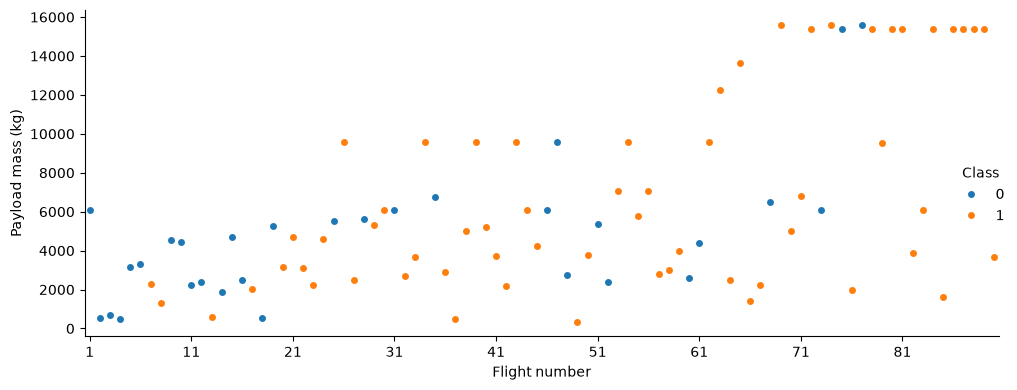

In [3]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

df = pd.read_csv(DATA / 'dataset_part_2.csv')

df.head(5)

g = sns.catplot(y='PayloadMass', x='FlightNumber', hue='Class', data=df, height=4, aspect=2.4)

g.ax.set_xticks(list(range(0, len(df), 10)), labels=df['FlightNumber'].iloc[::10].astype(str))

plt.xlabel('Flight number')

plt.ylabel('Payload mass (kg)')

plt.tight_layout()

save_current_figure()

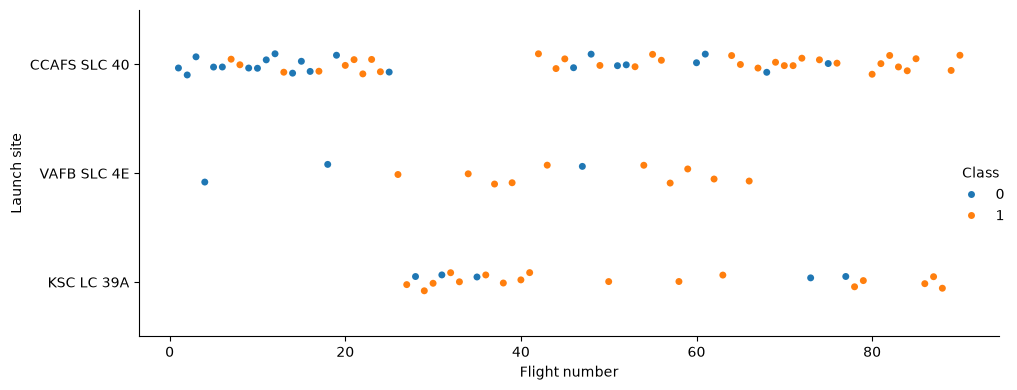

In [4]:
sns.catplot(x='FlightNumber', y='LaunchSite', hue='Class', data=df, height=4, aspect=2.4)

plt.xlabel('Flight number')

plt.ylabel('Launch site')

plt.tight_layout()

save_current_figure()

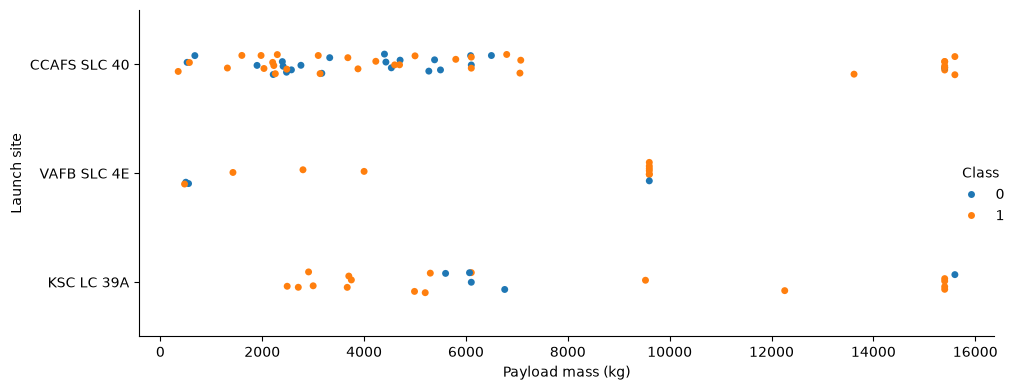

In [5]:
sns.catplot(x='PayloadMass', y='LaunchSite', hue='Class', data=df, height=4, aspect=2.4)

plt.xlabel('Payload mass (kg)')

plt.ylabel('Launch site')

plt.tight_layout()

save_current_figure()

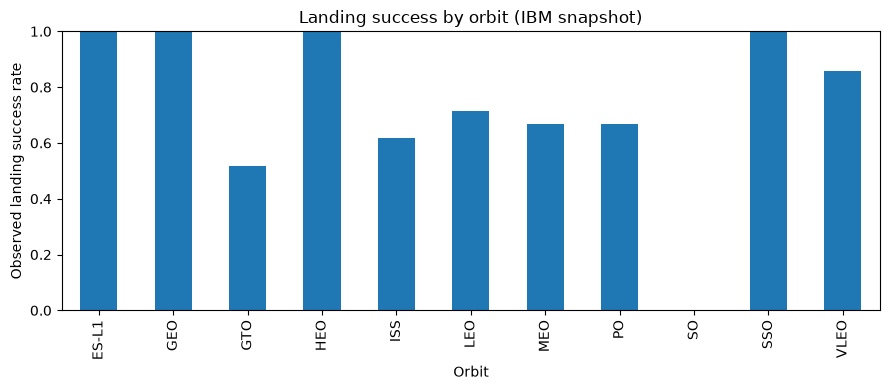

In [6]:
orbit_summary = df.groupby('Orbit')['Class'].agg(['size', 'sum', 'mean'])

orbit_summary['mean'].plot.bar(figsize=(9, 4), ylim=(0, 1), ylabel='Observed landing success rate', title='Landing success by orbit (IBM snapshot)')

plt.tight_layout()

save_current_figure()

,size,sum,mean
Orbit,,,
ES-L1,1,1,1.000000
GEO,1,1,1.000000
GTO,27,14,0.518519
HEO,1,1,1.000000
ISS,21,13,0.619048
LEO,7,5,0.714286
MEO,3,2,0.666667
PO,9,6,0.666667
SO,1,0,0.000000


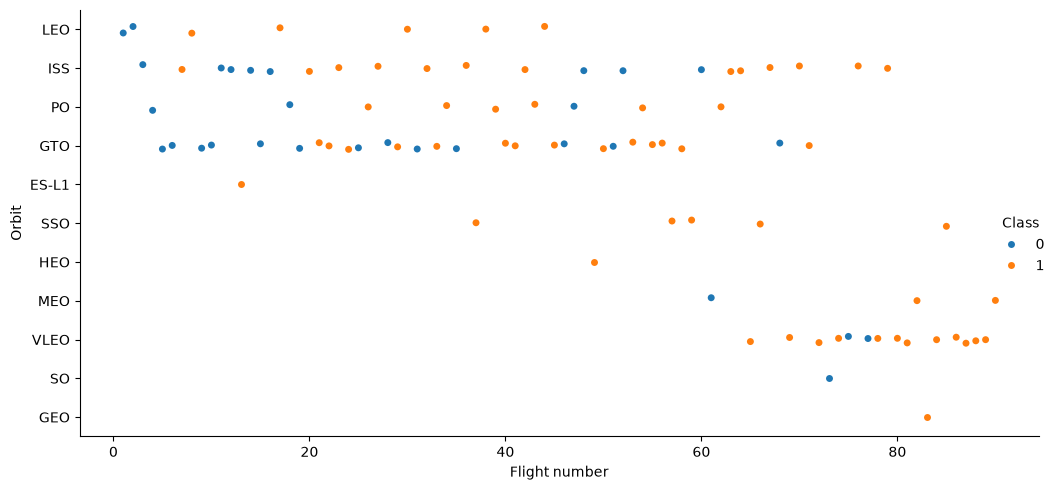

In [7]:
display(orbit_summary)

sns.catplot(x='FlightNumber', y='Orbit', hue='Class', data=df, height=5, aspect=2)

plt.xlabel('Flight number')

plt.ylabel('Orbit')

plt.tight_layout()

save_current_figure()

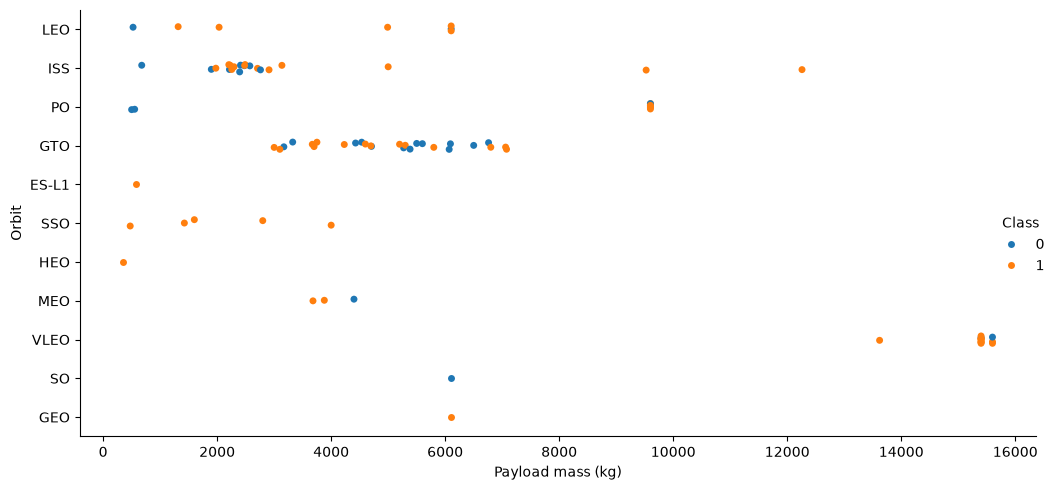

In [8]:
sns.catplot(x='PayloadMass', y='Orbit', hue='Class', data=df, height=5, aspect=2)

plt.xlabel('Payload mass (kg)')

plt.ylabel('Orbit')

plt.tight_layout()

save_current_figure()

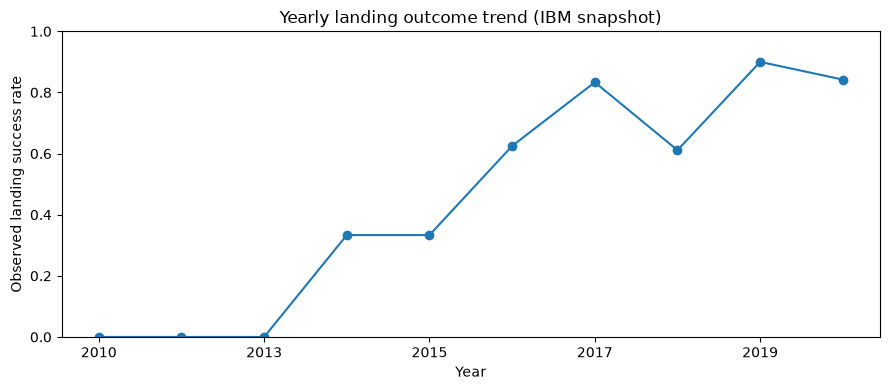

In [9]:
year = []

def Extract_year(date):
    for i in df['Date']:
        year.append(i.split('-')[0])
    return year

df['Year'] = Extract_year(df['Date'])

yearly_summary = df.groupby('Year')['Class'].agg(['size', 'sum', 'mean'])

yearly_summary['mean'].plot(marker='o', figsize=(9, 4), ylim=(0, 1), ylabel='Observed landing success rate', title='Yearly landing outcome trend (IBM snapshot)')

plt.tight_layout()

save_current_figure()

In [10]:
display(yearly_summary)

features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]

features.head()

features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])

features_one_hot.head()

features_one_hot = features_one_hot.astype('float64')

features_one_hot.head()

import json

assert features_one_hot.shape[0] == len(df) == 90

assert all((str(t) == 'float64' for t in features_one_hot.dtypes))

assert not features_one_hot.isna().any().any()

features_one_hot.to_csv(OUT / 'dataset_part_3.derived.csv', index=False)

reference = pd.read_csv(DATA / 'dataset_part_3.csv')

shared = sorted(set(reference.columns) & set(features_one_hot.columns))

assert np.allclose(reference[shared], features_one_hot[shared])

orbit_summary.to_csv(OUT / 'orbit_summary.csv')

yearly_summary.to_csv(OUT / 'yearly_summary.csv')

site_summary = df.groupby('LaunchSite')['Class'].agg(['size', 'sum', 'mean'])

display(site_summary)

result = {'rows': len(df), 'features_generated': features_one_hot.shape[1], 'official_reference_features': reference.shape[1], 'common_features_verified': len(shared), 'difference_explanation': 'Current pandas retains boolean inputs as 3 numeric columns; official precomputed file one-hot encodes them into 6 columns. Both encode the same observed booleans.', 'max_payload_VAFB': float(df.loc[df['LaunchSite'] == 'VAFB SLC 4E', 'PayloadMass'].max()), 'interpretation': 'Associations are descriptive; site, orbit, payload and time are confounded. Small orbit counts limit rate comparisons.'}

,size,sum,mean
Year,,,
2010,1,0,0.000000
2012,1,0,0.000000
2013,3,0,0.000000
2014,6,2,0.333333
2015,6,2,0.333333
2016,8,5,0.625000
2017,18,15,0.833333
2018,18,11,0.611111
2019,10,9,0.900000


,size,sum,mean
LaunchSite,,,
CCAFS SLC 40,55,33,0.600000
KSC LC 39A,22,17,0.772727
VAFB SLC 4E,13,10,0.769231


In [11]:
(OUT / 'RESULTS.json').write_text(json.dumps(result, indent=2))

print(json.dumps(result, indent=2))

{
  "rows": 90,
  "features_generated": 80,
  "official_reference_features": 83,
  "common_features_verified": 77,
  "difference_explanation": "Current pandas retains boolean inputs as 3 numeric columns; official precomputed file one-hot encodes them into 6 columns. Both encode the same observed booleans.",
  "max_payload_VAFB": 9600.0,
  "interpretation": "Associations are descriptive; site, orbit, payload and time are confounded. Small orbit counts limit rate comparisons."
}
